# A Linear Algebra Based Music Recommendation System Using Vector Similarity
**Course:** Mathematics for Aerospace/AI/Data (MFAD) – Mini Project

Songs are represented as **vectors**, the dataset as a **matrix**, and similarity as the **angle** between vectors.

| Concept | Where it is used |
|---|---|
| Vectors & matrices | Song feature vectors, feature matrix X |
| Normalisation | Min–max scaling of columns |
| Dot product & norms | Alignment and magnitude of vectors |
| Cosine similarity / angle | Similarity score |
| Projection, eigenvectors, PCA | 5-D → 2-D reduction and music map |

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.precision', 3)

## 1. Dataset → Feature matrix X
Each song is a vector **S = [energy, danceability, acousticness, valence, tempo]**. Stacking all song vectors as rows gives the matrix **X (n × 5)**. *(Values are approximate/illustrative; replace with a Spotify CSV for real data.)*

In [2]:
FEATURES = ["energy","danceability","acousticness","valence","tempo"]
SONGS = [
("Blinding Lights","The Weeknd",.80,.51,.00,.33,171),("Save Your Tears","The Weeknd",.68,.65,.02,.64,118),
("Levitating","Dua Lipa",.83,.70,.06,.91,103),("Don't Start Now","Dua Lipa",.79,.79,.01,.68,124),
("Shape of You","Ed Sheeran",.65,.83,.58,.93,96),("Perfect","Ed Sheeran",.45,.60,.16,.52,95),
("Thinking Out Loud","Ed Sheeran",.45,.78,.47,.59,79),("Watermelon Sugar","Harry Styles",.82,.55,.12,.56,95),
("Uptown Funk","Bruno Mars",.61,.86,.01,.93,115),("Happy","Pharrell Williams",.82,.65,.22,.96,160),
("Someone Like You","Adele",.33,.56,.89,.30,135),("Stay With Me","Sam Smith",.42,.42,.55,.18,84),
("Bad Guy","Billie Eilish",.43,.70,.33,.56,135),("Lovely","Billie Eilish",.30,.35,.93,.12,115),
("Believer","Imagine Dragons",.78,.78,.06,.67,125),("Radioactive","Imagine Dragons",.78,.45,.10,.24,136),
("Counting Stars","OneRepublic",.71,.66,.07,.48,122),("Stressed Out","Twenty One Pilots",.64,.73,.05,.65,170),
("Sunflower","Post Malone",.48,.76,.56,.93,90),("Circles","Post Malone",.76,.69,.19,.55,120),
("Rockstar","Post Malone",.52,.59,.12,.12,160),("Lose Yourself","Eminem",.73,.69,.01,.06,171),
("SICKO MODE","Travis Scott",.73,.83,.01,.45,155),("God's Plan","Drake",.45,.75,.03,.36,77),
("Hotline Bling","Drake",.62,.89,.01,.81,135),("Bohemian Rhapsody","Queen",.40,.39,.29,.23,72),
("Hotel California","Eagles",.58,.58,.01,.60,147),("Sweet Child O' Mine","Guns N' Roses",.91,.45,.00,.83,125),
("Smells Like Teen Spirit","Nirvana",.91,.50,.00,.72,117),("Numb","Linkin Park",.86,.50,.00,.24,110),
("Yesterday","The Beatles",.18,.34,.88,.32,97),("Fix You","Coldplay",.42,.21,.16,.12,138),
("Viva La Vida","Coldplay",.62,.49,.09,.42,138),("Shallow","Lady Gaga",.39,.57,.38,.30,96),
("Dance Monkey","Tones and I",.59,.82,.69,.52,98),("Señorita","Shawn Mendes",.54,.76,.04,.75,117),
("Tum Hi Ho","Arijit Singh",.45,.52,.60,.30,86),("Kala Chashma","Badshah",.88,.78,.05,.85,102)]
df = pd.DataFrame(SONGS, columns=["name","artist"]+FEATURES)
names = df["name"].tolist()
X_raw = df[FEATURES].to_numpy(dtype=float)
print("Feature matrix shape:", X_raw.shape)
df.head()

Feature matrix shape: (38, 5)


,name,artist,energy,danceability,acousticness,valence,tempo
0,Blinding Lights,The Weeknd,0.80,0.51,0.00,0.33,171
1,Save Your Tears,The Weeknd,0.68,0.65,0.02,0.64,118
2,Levitating,Dua Lipa,0.83,0.70,0.06,0.91,103
3,Don't Start Now,Dua Lipa,0.79,0.79,0.01,0.68,124
4,Shape of You,Ed Sheeran,0.65,0.83,0.58,0.93,96


## 2. Normalisation
Tempo is in BPM (~70–170) while other features lie in [0, 1], so tempo would dominate any dot product. Each **column** is rescaled with  
$$x' = \frac{x-\min}{\max-\min}$$

In [3]:
col_min, col_max = X_raw.min(axis=0), X_raw.max(axis=0)
X = (X_raw - col_min) / (col_max - col_min)
print("column min:", col_min); print("column max:", col_max)
pd.DataFrame(X, index=names, columns=FEATURES).head()

column min: [ 0.18  0.21  0.    0.06 72.  ]
column max: [  0.91   0.89   0.93   0.96 171.  ]


,energy,danceability,acousticness,valence,tempo
Blinding Lights,0.849,0.441,0.000,0.300,1.000
Save Your Tears,0.685,0.647,0.022,0.644,0.465
Levitating,0.890,0.721,0.065,0.944,0.313
Don't Start Now,0.836,0.853,0.011,0.689,0.525
Shape of You,0.644,0.912,0.624,0.967,0.242


## 3. Dot product, norms and cosine similarity (by hand)
$$\cos\theta=\frac{S_1\cdot S_2}{\|S_1\|\,\|S_2\|}$$
We compute every component step by step for one pair of songs, then verify with NumPy.

In [4]:
def idx(title): return names.index(title)

def explain_pair(t1, t2):
    a, b = X[idx(t1)], X[idx(t2)]
    print(f"S1 = {t1}\nS2 = {t2}\n")
    print("S1 (raw)        =", X_raw[idx(t1)]); print("S2 (raw)        =", X_raw[idx(t2)])
    print("S1' (normalised) =", a);               print("S2' (normalised) =", b)
    terms = a * b
    print("\nElement-wise products :", terms)
    dp = terms.sum();  print(f"Dot product S1'·S2'  = {dp:.4f}")
    n1, n2 = np.sqrt((a**2).sum()), np.sqrt((b**2).sum())
    print(f"Norm ||S1'|| = {n1:.4f},  Norm ||S2'|| = {n2:.4f}")
    cos = dp / (n1 * n2)
    print(f"cos(theta) = {dp:.4f} / ({n1:.4f} x {n2:.4f}) = {cos:.4f}")
    print(f"theta = arccos(cos) = {np.degrees(np.arccos(cos)):.2f} degrees")
    assert np.isclose(cos, np.dot(a,b)/(np.linalg.norm(a)*np.linalg.norm(b)))  # NumPy check
    return cos

explain_pair("Blinding Lights", "Lose Yourself");

S1 = Blinding Lights
S2 = Lose Yourself

S1 (raw)        = [  0.8    0.51   0.     0.33 171.  ]
S2 (raw)        = [  0.73   0.69   0.01   0.06 171.  ]
S1' (normalised) = [0.8493 0.4412 0.     0.3    1.    ]
S2' (normalised) = [0.7534 0.7059 0.0108 0.     1.    ]

Element-wise products : [0.6399 0.3114 0.     0.     1.    ]
Dot product S1'·S2'  = 1.9513
Norm ||S1'|| = 1.4163,  Norm ||S2'|| = 1.4374
cos(theta) = 1.9513 / (1.4163 x 1.4374) = 0.9585
theta = arccos(cos) = 16.56 degrees


## 4. Similarity of *all* songs at once (matrix operation)
With unit vectors $\hat X$ (each row divided by its norm), the full similarity matrix is one matrix product:
$$\text{Sim}=\hat X\,\hat X^{T}$$

Similarity matrix shape: (38, 38) | diagonal all 1: True


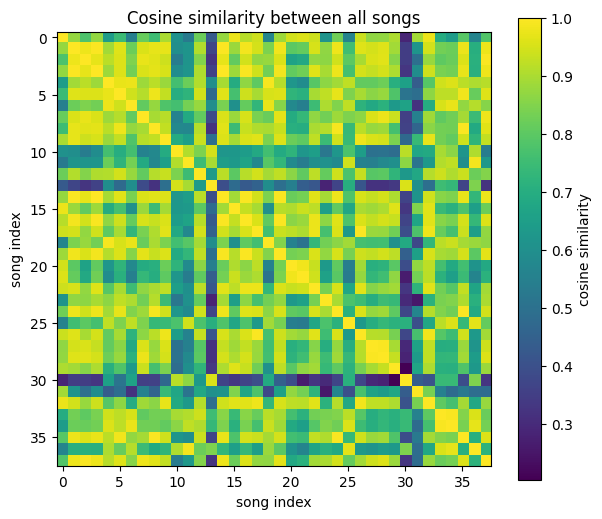

In [5]:
norms = np.linalg.norm(X, axis=1, keepdims=True)
X_hat = X / norms                  # unit vectors
SIM = X_hat @ X_hat.T              # n x n cosine-similarity matrix
print("Similarity matrix shape:", SIM.shape, "| diagonal all 1:", np.allclose(np.diag(SIM), 1))
plt.figure(figsize=(7,6)); plt.imshow(SIM, cmap="viridis"); plt.colorbar(label="cosine similarity")
plt.title("Cosine similarity between all songs"); plt.xlabel("song index"); plt.ylabel("song index"); plt.show()

## 5. Recommendation: similarity scores → Top-N ranking

In [6]:
def recommend(favourites, n=5, X_space=None):
    """favourites: song title or list of titles. Preference vector = mean of their vectors."""
    S = X if X_space is None else X_space
    favs = [favourites] if isinstance(favourites, str) else list(favourites)
    ids = [idx(f) for f in favs]
    p = S[ids].mean(axis=0)                                    # user preference vector
    sims = (S @ p) / (np.linalg.norm(S, axis=1) * np.linalg.norm(p))
    sims[ids] = -np.inf                                        # exclude the chosen songs
    top = np.argsort(sims)[::-1][:n]
    return pd.DataFrame({"Rank": range(1, n+1), "Song": [names[i] for i in top],
                         "Artist": [df.artist[i] for i in top], "Similarity": sims[top].round(4)}).set_index("Rank")

favourite = "Blinding Lights"      # <-- change the song here
recommend(favourite, n=5)

,Song,Artist,Similarity
Rank,,,
1,Radioactive,Imagine Dragons,0.978
2,Viva La Vida,Coldplay,0.976
3,Lose Yourself,Eminem,0.959
4,Rockstar,Post Malone,0.946
5,Stressed Out,Twenty One Pilots,0.940


### Taste profile (several favourites → one preference vector)

In [7]:
recommend(["Blinding Lights", "Believer", "Numb"], n=5)

,Song,Artist,Similarity
Rank,,,
1,Counting Stars,OneRepublic,0.984
2,Viva La Vida,Coldplay,0.979
3,Radioactive,Imagine Dragons,0.976
4,SICKO MODE,Travis Scott,0.970
5,Circles,Post Malone,0.969


## 6. Principal Component Analysis (eigenvectors & projection)
To see the 5-D music space, we find the directions of greatest variance:
1. Centre the data: $X_c = X' - \bar{x}$  
2. Covariance matrix: $C=\frac{X_c^{T}X_c}{n-1}$  
3. Solve $C\,v=\lambda v$ (eigenvalues λ, eigenvectors v)  
4. **Project** onto the top-2 eigenvectors: $Z = X_c\,V_2$

In [8]:
Xc = X - X.mean(axis=0)
Cov = Xc.T @ Xc / (len(X) - 1)
vals, vecs = np.linalg.eigh(Cov)
order = np.argsort(vals)[::-1]; vals, vecs = vals[order], vecs[:, order]
explained = vals / vals.sum()
print("Covariance matrix:\n", pd.DataFrame(Cov, index=FEATURES, columns=FEATURES).round(4))
print("\nEigenvalues       :", vals)
print("Explained variance:", (explained*100).round(1), "%")
print("Top-2 components keep", f"{explained[:2].sum():.1%}", "of the information")
print("\nEigenvectors (loadings) for PC1, PC2:")
print(pd.DataFrame(vecs[:, :2], index=FEATURES, columns=["PC1","PC2"]).round(3))
Z = Xc @ vecs[:, :2]               # projection onto 2-D

Covariance matrix:
               energy  danceability  acousticness  valence  tempo
energy         0.068         0.018        -0.056    0.034  0.024
danceability   0.018         0.059        -0.018    0.045  0.002
acousticness  -0.056        -0.018         0.093   -0.022 -0.034
valence        0.034         0.045        -0.022    0.088 -0.006
tempo          0.024         0.002        -0.034   -0.006  0.077

Eigenvalues       : [0.1848 0.1056 0.0474 0.029  0.0177]
Explained variance: [48.1 27.5 12.3  7.6  4.6] %
Top-2 components keep 75.5% of the information

Eigenvectors (loadings) for PC1, PC2:
                PC1    PC2
energy       -0.517  0.106
danceability -0.327 -0.400
acousticness  0.588 -0.328
valence      -0.450 -0.618
tempo        -0.277  0.582


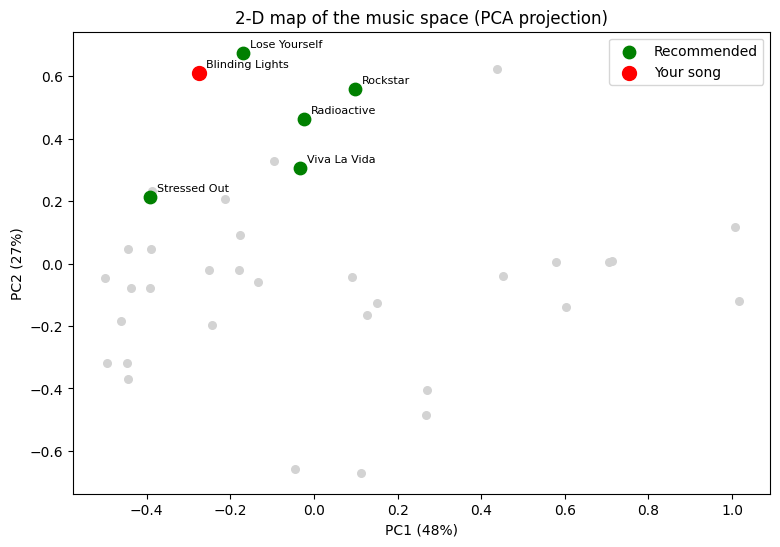

In [9]:
rec = recommend("Blinding Lights", 5)
fav_i = idx("Blinding Lights"); rec_i = [idx(s) for s in rec["Song"]]
plt.figure(figsize=(9,6))
plt.scatter(Z[:,0], Z[:,1], c="lightgray", s=30)
plt.scatter(Z[rec_i,0], Z[rec_i,1], c="green", s=80, label="Recommended")
plt.scatter(Z[fav_i,0], Z[fav_i,1], c="red", s=100, label="Your song")
for i in rec_i + [fav_i]: plt.annotate(names[i], Z[i], xytext=(5,4), textcoords="offset points", fontsize=8)
plt.xlabel(f"PC1 ({explained[0]:.0%})"); plt.ylabel(f"PC2 ({explained[1]:.0%})")
plt.title("2-D map of the music space (PCA projection)"); plt.legend(); plt.show()

## 7. Does the reduced 2-D space give similar recommendations?

In [10]:
full = recommend("Blinding Lights", 5)
red  = recommend("Blinding Lights", 5, X_space=Z)
print("Full 5-D space:", list(full.Song)); print("PCA 2-D space :", list(red.Song))
print("Overlap:", len(set(full.Song) & set(red.Song)), "of 5")

Full 5-D space: ['Radioactive', 'Viva La Vida', 'Lose Yourself', 'Rockstar', 'Stressed Out']
PCA 2-D space : ['Numb', 'Lose Yourself', 'Viva La Vida', 'Radioactive', 'Hotel California']
Overlap: 3 of 5


## 8. Conclusion
* Songs → vectors, dataset → matrix **X**; normalisation made all features comparable.
* **Dot product** measures alignment, **norms** remove magnitude, **cosine/angle** gives the similarity score.
* One matrix product $\hat X\hat X^T$ scores all song pairs; sorting gives **Top-N recommendations**.
* **Eigenvectors/PCA** compress 5 features to 2 while keeping most of the information and give a visual music map.

**Limitations / future work:** richer datasets (Spotify), more features, user listening history, and comparing with collaborative filtering.